## Implementing a RNN for Review Classification using IMDB Dataset Compare simple RNN, LSTM and GRU

##### Importing Libraries and Loading the Dataset
First, we need to import the necessary libraries and load the IMDB dataset. The IMDB dataset is a collection of 50,000 movie reviews, which are labeled as either positive or negative. We’ll use this dataset to train our model.

In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
# # Ensure a Single OpenMP Runtime. As a temporary workaround, you can set the environment variable KMP_DUPLICATE_LIB_OK to TRUE

In [ ]:
  import numpy as np
  import tensorflow as tf
  from tensorflow.keras.datasets import imdb
  from tensorflow.keras.preprocessing import sequence
  from tensorflow.keras.models import Sequential
  from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
  import matplotlib.pyplot as plt

  # Set random seed for reproducibility
  np.random.seed(7)
  tf.random.set_seed(7)

  # Load the IMDB dataset
  max_features = 10000  # Number of words to consider as features
  maxlen = 500  # Cut texts after this number of words (among top max_features most common words)
  batch_size = 32

  (input_train, y_train), (input_test, y_test) = imdb.load_data(num_words=max_features)

  # Pad sequences to ensure uniform input size
  input_train = sequence.pad_sequences(input_train, maxlen=maxlen)
  input_test = sequence.pad_sequences(input_test, maxlen=maxlen)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


- np.random.seed(7) and tf.random.set_seed(7): Setting the random seed ensures that the results are reproducible.
- imdb.load_data(num_words=max_features): Loads the IMDB dataset, keeping only the top max_features most frequently occurring words.
- sequence.pad_sequences: Pads the sequences to ensure they all have the same length (maxlen), which is necessary for batch processing.


#### Building and Training the Simple RNN Model
- Embedding(max_features, 32): The Embedding layer converts integer sequences into dense vectors of fixed size (32 in this case).
- SimpleRNN(32): Adds a simple RNN layer with 32 units.
- Dense(1, activation='sigmoid'): Adds a dense layer with a sigmoid activation function to output a probability (since this is a binary classification problem).
- model.compile: Configures the model for training. We use the RMSprop optimizer and binary cross-entropy loss function.
- model.fit: Trains the model for 10 epochs with a batch size of 32, using 20% of the training data for validation.

In [ ]:
# Build the model
model = Sequential()
model.add(Embedding(max_features, 32))
model.add(SimpleRNN(32))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(input_train, y_train, epochs=10, batch_size=batch_size, validation_split=0.2)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 44ms/step - accuracy: 0.5665 - loss: 0.6686 - val_accuracy: 0.7816 - val_loss: 0.4674
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 57ms/step - accuracy: 0.8157 - loss: 0.4131 - val_accuracy: 0.8272 - val_loss: 0.3930
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.8635 - loss: 0.3283 - val_accuracy: 0.8472 - val_loss: 0.3601
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.8963 - loss: 0.2522 - val_accuracy: 0.8100 - val_loss: 0.4291
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 60ms/step - accuracy: 0.9198 - loss: 0.2040 - val_accuracy: 0.8306 - val_loss: 0.3997
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.9475 - loss: 0.1406 - val_accuracy: 0.8338 - val_loss: 0.4597
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 60ms/step - accuracy: 0.9657 - loss: 0.1002 - val_accuracy: 0.7968 - val_loss: 0.5892
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 55ms/step - accuracy: 0.9696 - loss: 0.0865 - 

##### Evaluating the Simple RNN Model
- model.evaluate: Evaluates the model on the test data and returns the loss and accuracy.

In [ ]:
# Evaluate the model
test_loss, test_acc = model.evaluate(input_test, y_test)
print(f'Test Accuracy: {test_acc:.2f}')

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7951 - loss: 0.7781
Test Accuracy: 0.79


## Analyzing and Visualizing Performance Change with LSTM and GRU
#### Building and Training the LSTM Model
LSTM (Long Short-Term Memory) networks are a type of RNN designed to capture long-term dependencies in sequences. They are more complex than simple RNNs and can remember information for longer periods.
- tf.keras.layers.LSTM(32): Adds an LSTM layer with 32 units.

In [ ]:
# Build the LSTM model
model_lstm = Sequential()
model_lstm.add(Embedding(max_features, 32))
model_lstm.add(tf.keras.layers.LSTM(32))
model_lstm.add(Dense(1, activation='sigmoid'))

# Compile the model
model_lstm.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_lstm = model_lstm.fit(input_train, y_train, epochs=10, batch_size=batch_size, validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.6827 - loss: 0.5711 - val_accuracy: 0.8630 - val_loss: 0.3388
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.8682 - loss: 0.3275 - val_accuracy: 0.8584 - val_loss: 0.3398
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.8979 - loss: 0.2675 - val_accuracy: 0.8624 - val_loss: 0.3289
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9141 - loss: 0.2318 - val_accuracy: 0.8636 - val_loss: 0.3262
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9237 - loss: 0.2069 - val_accuracy: 0.8756 - val_loss: 0.3099
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9321 - loss: 0.1894 - val_accuracy: 0.8724 - val_loss: 0.3271
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9378 - loss: 0.1773 - val_accuracy: 0.8712 - val_loss: 0.3603
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9456 - loss: 0.1602 - 

##### Building and Training the GRU Model
GRU (Gated Recurrent Unit) networks are a simpler variant of LSTMs. They also capture long-term dependencies but with fewer parameters, making them faster to train.
- tf.keras.layers.GRU(32): Adds a GRU layer with 32 units.

In [ ]:
# Build the GRU model
model_gru = Sequential()
model_gru.add(Embedding(max_features, 32))
model_gru.add(tf.keras.layers.GRU(32))
model_gru.add(Dense(1, activation='sigmoid'))

# Compile the model
model_gru.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_gru = model_gru.fit(input_train, y_train, epochs=10, batch_size=batch_size, validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6449 - loss: 0.6001 - val_accuracy: 0.8508 - val_loss: 0.3562
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.8553 - loss: 0.3476 - val_accuracy: 0.8724 - val_loss: 0.3125
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.8924 - loss: 0.2751 - val_accuracy: 0.8826 - val_loss: 0.2872
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9119 - loss: 0.2377 - val_accuracy: 0.8696 - val_loss: 0.3251
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9231 - loss: 0.2108 - val_accuracy: 0.8778 - val_loss: 0.3201
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9385 - loss: 0.1725 - val_accuracy: 0.8758 - val_loss: 0.3382
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9457 - loss: 0.1571 - val_accuracy: 0.8822 - val_loss: 0.3300
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9571 - loss: 0.1333 - 

##### Visualizing the Performance
visualize the training and validation accuracy for each model to compare their performance.
- plot_history: A function to plot the training and validation accuracy for each model.
- plt.plot: Plots the training and validation accuracy for each epoch.

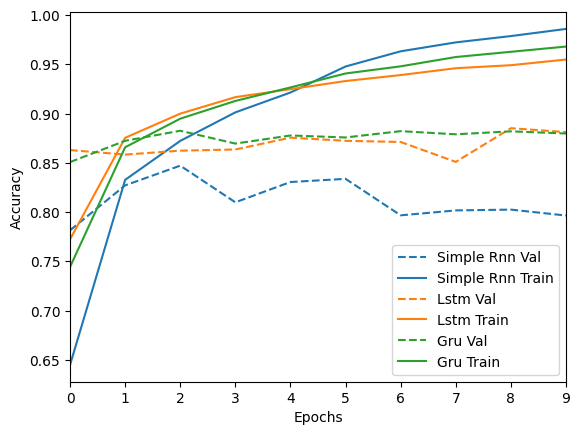

In [ ]:
# Function to plot training history
def plot_history(histories, key='accuracy'):


    for name, history in histories:
        val = plt.plot(history.epoch, history.history['val_'+key], '--', label=name.title()+' Val')
        plt.plot(history.epoch, history.history[key], color=val[0].get_color(), label=name.title()+' Train')

    plt.xlabel('Epochs')
    plt.ylabel(key.replace('_',' ').title())
    plt.legend()
    plt.xlim([0,max(history.epoch)])
    plt.show()

# Plot the accuracy and loss for each model
plot_history([('Simple RNN', history), ('LSTM', history_lstm), ('GRU', history_gru)])


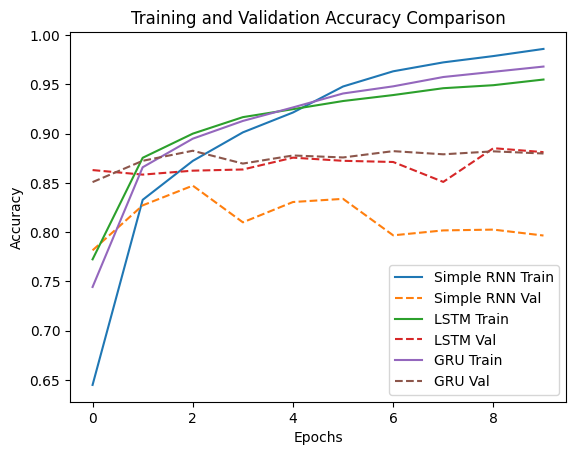

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy for all three models
plt.plot(history.history['accuracy'], label='Simple RNN Train')
plt.plot(history.history['val_accuracy'], '--', label='Simple RNN Val')

plt.plot(history_lstm.history['accuracy'], label='LSTM Train')
plt.plot(history_lstm.history['val_accuracy'], '--', label='LSTM Val')

plt.plot(history_gru.history['accuracy'], label='GRU Train')
plt.plot(history_gru.history['val_accuracy'], '--', label='GRU Val')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy Comparison')
plt.legend()
plt.show()
